# 02 · Exploratorio: cuándo, cuánto y dónde

Eventos por año, por magnitud y por profundidad, y mapas de epicentros coloreados por profundidad: la subducción de la placa de Nazca.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

from sismos import config, analisis, graficos
from sismos import gutenberg_richter as gr

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
ecuador = pd.read_parquet(config.CATALOGO_ECUADOR)
mundo = pd.read_parquet(config.CATALOGO_CINTURON)
historico = pd.read_parquet(config.CATALOGO_HISTORICO)
resultados = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
print(f"Ecuador: {len(ecuador):,} sismos · mundo M≥5: {len(mundo):,} · histórico M≥6: {len(historico):,}")

Ecuador: 3,214 sismos · mundo M≥5: 87,784 · histórico M≥6: 139


In [2]:
pd.Series(resultados['exploratorio']).drop(['mayor', 'pct_por_clase_profundidad_sin_fijas', 'pendiente_placa'])

eventos                     3214
eventos_m5                  1280
eventos_m6                    73
eventos_m7                    16
anio_mas_activo             2016
eventos_anio_mas_activo      201
eventos_por_anio_mediana    48.0
profundidad_mediana_km      35.0
dtype: object

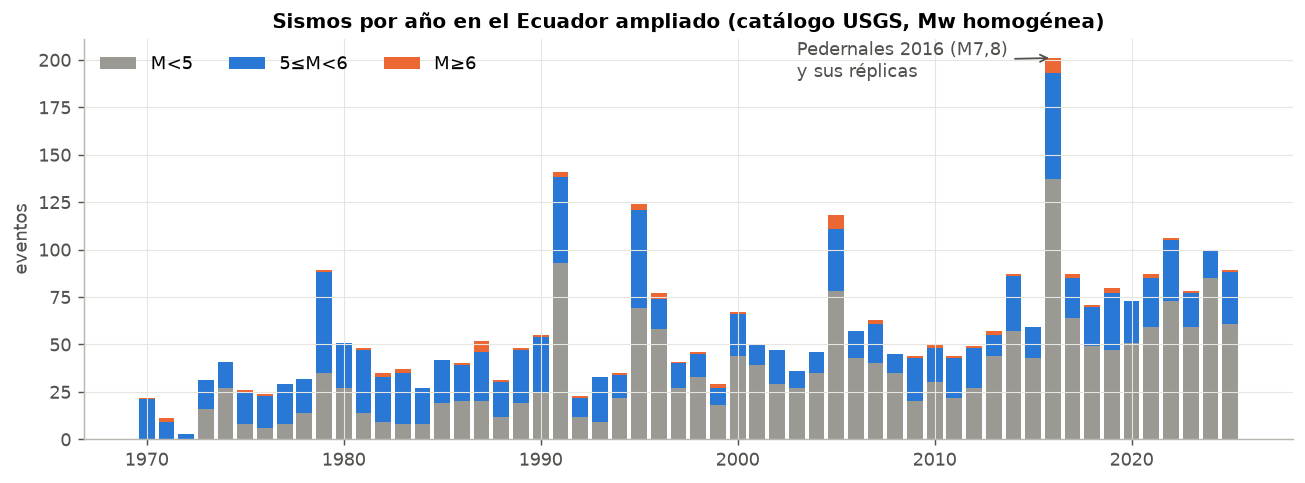

In [3]:
display(Image(config.FIGURAS / '02_eventos_por_anio.png'))

In [4]:
ecuador.groupby('anio').size().sort_values(ascending=False).head(5).rename('sismos')

anio
2016    201
1991    141
1995    124
2005    118
2022    106
Name: sismos, dtype: int64

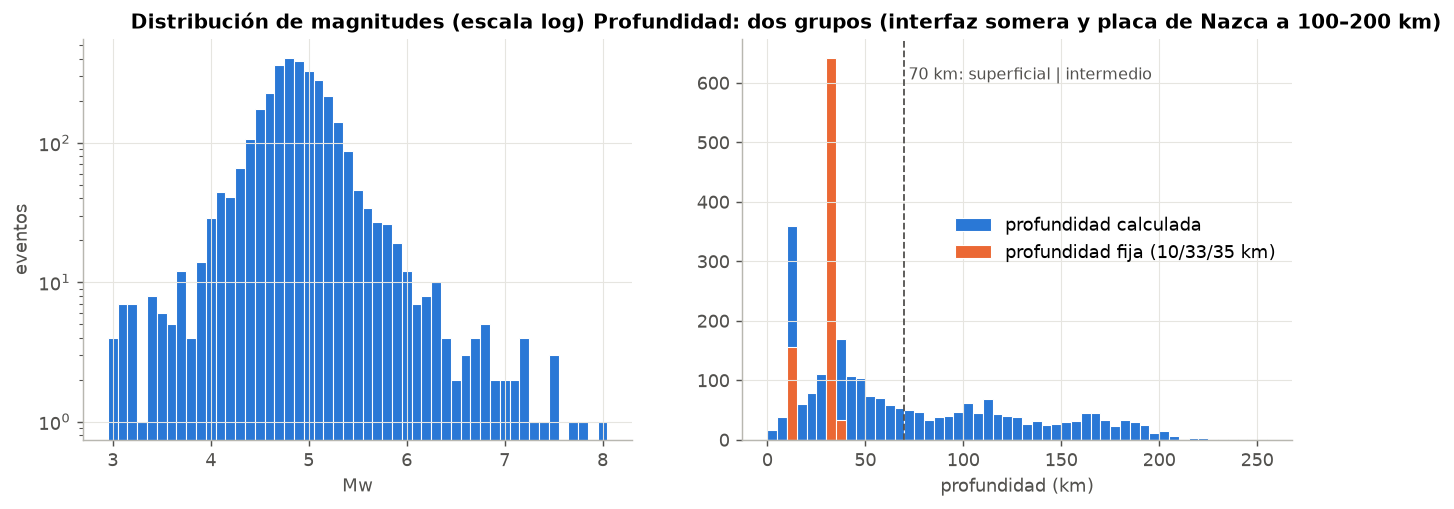

In [5]:
display(Image(config.FIGURAS / '03_magnitud_y_profundidad.png'))

In [6]:
resultados['exploratorio']['pct_por_clase_profundidad_sin_fijas']

{'Superficial (<70 km)': 58.1,
 'Intermedia (70–300 km)': 41.9,
 'Profunda (>300 km)': 0.0}

## Mapa y corte de la subducción

Los sismos someros se alinean con la costa (contacto entre placas); hacia el este la profundidad crece porque la placa de Nazca se hunde bajo la Sudamericana.

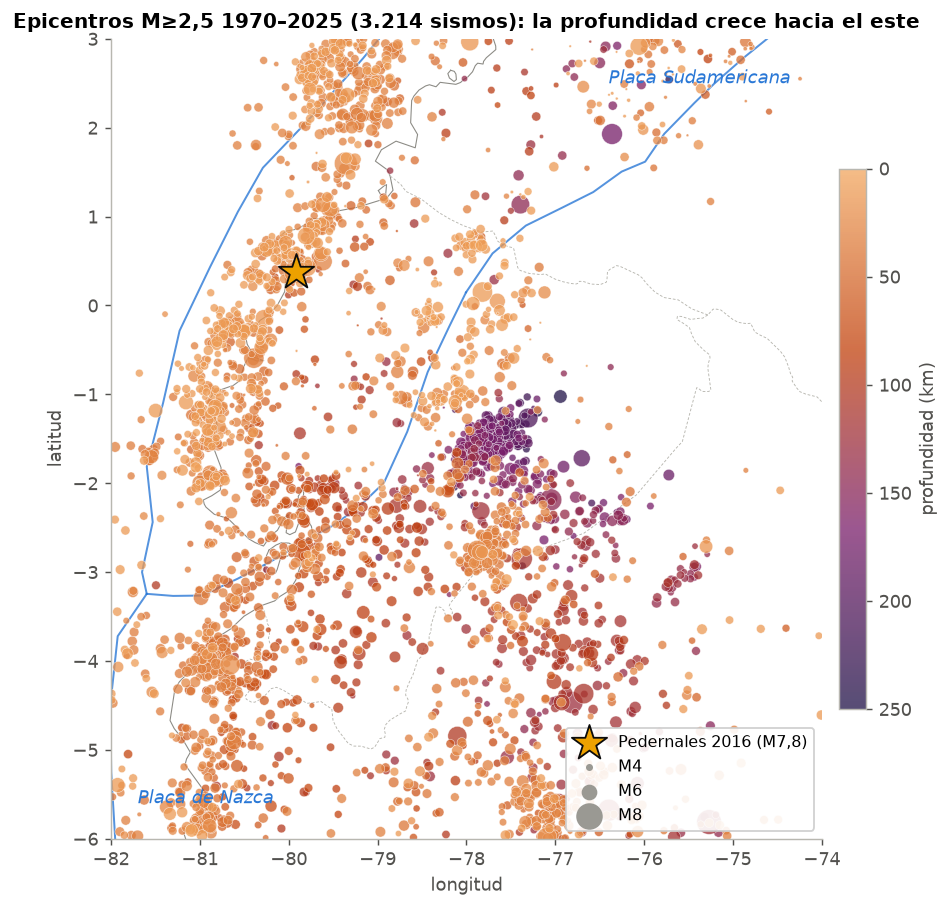

In [7]:
display(Image(config.FIGURAS / '04_mapa_epicentros_ecuador.png'))

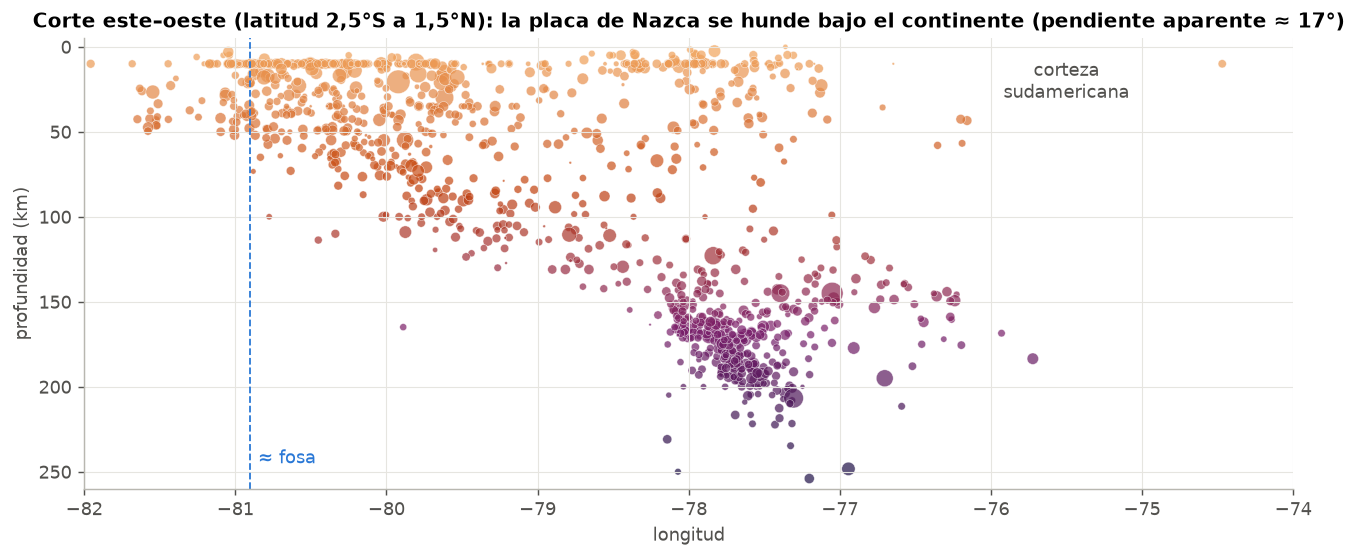

In [8]:
display(Image(config.FIGURAS / '05_perfil_subduccion.png'))

In [9]:
resultados['exploratorio']['pendiente_placa']

{'n': 710,
 'km_profundidad_por_km': 0.2962358492491478,
 'angulo_grados': 16.501177483258175}

Sismos M≥7 del catálogo 1970–2025:

In [10]:
ecuador[ecuador['mw'] >= 7][['tiempo', 'mw', 'tipo_mag', 'profundidad_km', 'lugar']]

,tiempo,mw,tipo_mag,profundidad_km,lugar
6,1970-12-10 04:34:40.150000+00:00,7.2,mw,19.20,"9 km ENE of Papayal, Peru"
30,1971-07-27 02:02:49.080000+00:00,7.4,mw,113.30,"98 km ESE of Sucúa, Ecuador"
246,1979-12-12 07:59:03.300000+00:00,7.7,ms,24.00,"56 km NW of Valdez, Ecuador"
450,1983-04-12 12:07:54.520000+00:00,7.0,mw,104.20,"92 km NNE of La Peca, Peru"
595,1987-03-06 04:10:41.960000+00:00,7.2,mw,10.00,"29 km SSE of Pimampiro, Ecuador"
813,1991-04-05 04:19:49.520000+00:00,7.1,mw,19.80,"11 km NE of Rioja, Peru"
1037,1995-10-03 01:51:23.900000+00:00,7.0,mw,24.40,"45 km SE of Sucúa, Ecuador"
1246,1997-10-28 06:15:17.330000+00:00,7.2,mwc,112.00,"51 km N of Barranca, Peru"
1273,1998-08-04 18:59:20.100000+00:00,7.2,mwc,33.00,"3 km E of Bahía de Caráquez, Ecuador"
1663,2005-09-26 01:55:37.670000+00:00,7.5,mwb,115.00,"39 km NW of Yurimaguas, Peru"


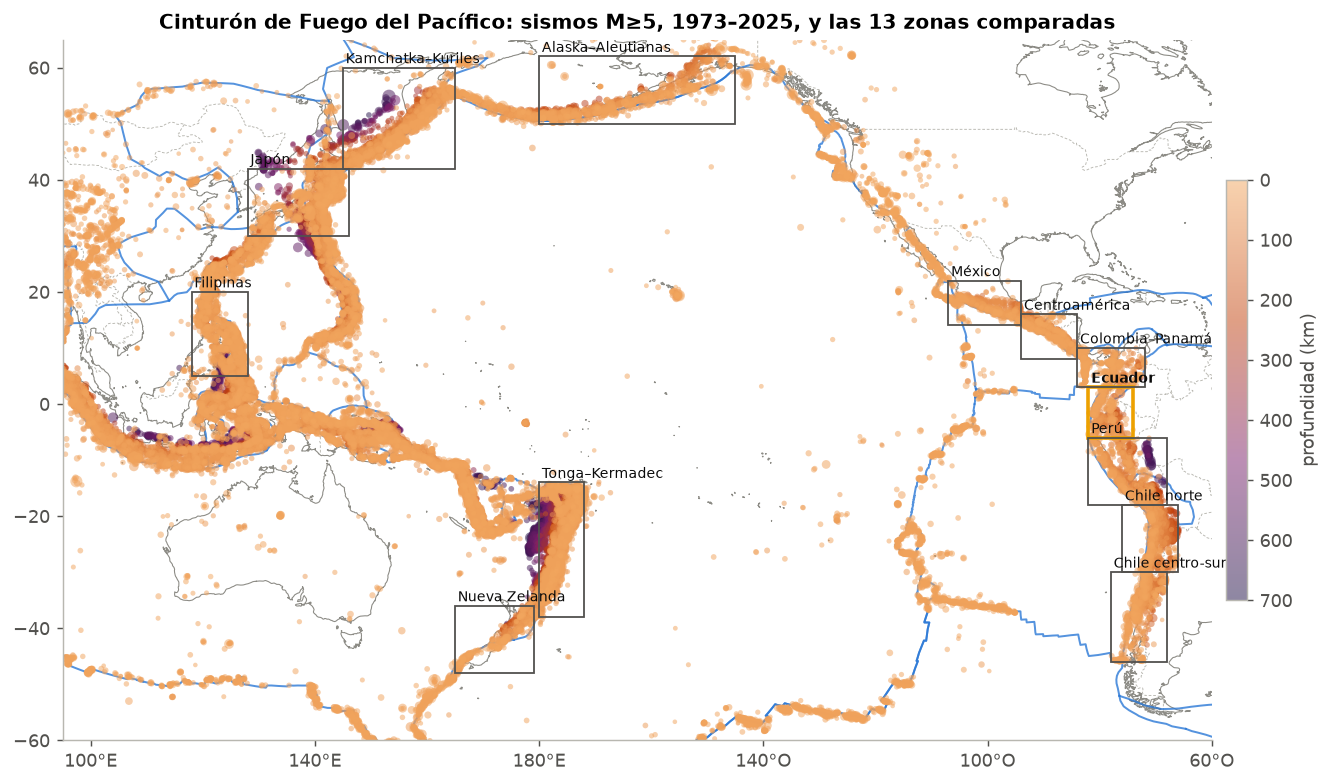

In [11]:
display(Image(config.FIGURAS / '08_mapa_cinturon_de_fuego.png'))